
# MOAD docking runtime vs. physical descriptors and molecular embeddings

This notebook analyses two complementary representations of pre-docking complex information:

1. **Simple physical descriptors** motivated by docking-runtime literature.
2. **Sean-style learned complex embeddings**: mean-pooled protein ESM-C-600M graph features concatenated with the 384-D ligand ChemBERTa vector.

The objective is not to build the final cost predictor here. It is to determine, with interpretable diagnostics, **what runtime signal each representation contains, whether the signal is algorithm-specific, and whether physical descriptors add information beyond the learned embeddings**.

### Primary physical descriptors

- ligand heavy-atom count;
- ligand rotatable-bond count;
- total protein residue count;
- ligand-centred pocket heavy-atom count.

Pocket bounding-box volume is still extracted as a sensitivity variable, but is not used in the main multivariate comparison because it is strongly correlated with pocket atom count and is an axis-aligned structural proxy rather than the actual docking search box.

### Why not correlate all embedding dimensions individually?

The ESM-C/ChemBERTa coordinates are latent representation dimensions, not individually meaningful physical variables. Inspecting 1,536 marginal correlations would create a multiple-comparison-heavy, coordinate-dependent picture. Instead, the notebook uses **cross-validated regularised linear probes** as an aggregate measure of how much runtime information is linearly recoverable from each representation.

References:
- Trott, O. & Olson, A. J. *AutoDock Vina: improving the speed and accuracy of docking with a new scoring function, efficient optimization, and multithreading.* J. Comput. Chem. 31, 455–461 (2010). DOI: 10.1002/jcc.21334.
- Tai, H. K., Jusoh, S. A. & Siu, S. W. I. *Chaos-embedded particle swarm optimization approach for protein-ligand docking and virtual screening.* J. Cheminform. 10, 62 (2018). DOI: 10.1186/s13321-018-0320-9.


In [1]:

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem
from rdkit.Chem import rdMolDescriptors

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_absolute_error

DATA_ROOT = Path("/data1/home/jw1017/AS_Dock/data/MolAS")
RUNTIME_CSV = DATA_ROOT / "moad_runtime_trimmed.csv"
LIGAND_DIR = DATA_ROOT / "ligand_sdf_files"
PROTEIN_DIR = DATA_ROOT / "protein_pdb_files"

OUTPUT_DIR = DATA_ROOT / "physical_runtime_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

POCKET_RADIUS_A = 6.0

runtime = pd.read_csv(RUNTIME_CSV)
runtime.head()


,PDB_CCD_ID,surfdock_runtime,unimol_runtime,diffdock_runtime,diffdock_l_runtime,gnina_runtime,autodock_runtime,smina_runtime
0,19gs_BSP_A_210,2.263974,13.75,18.056119,21.760456,1.711605,2.440576,0.702772
1,19gs_BSP_B_210,2.353717,17.23,20.320549,17.245006,1.690263,2.379304,0.671570
2,1a49_OXL_A_533,2.164571,28.33,30.149476,28.001163,26.874878,6.861748,0.741339
3,1a49_OXL_D_2333,2.031792,23.90,30.149476,28.001163,17.972973,7.571683,0.708913
4,1a49_OXL_F_4133,2.261405,33.36,30.149476,28.001163,27.762517,6.675899,0.718940



## 1. File matching and descriptor extraction

`PDB_CCD_ID` is used as the authoritative filter: only complexes appearing in the 3,179-row runtime table are processed, even if the structure folders contain additional complexes.

Expected filenames:
- `{PDB_CCD_ID}_ligand.sdf`
- `{PDB_CCD_ID}_protein.pdb`

The protein graph and ligand graph files are **not needed** for these descriptors; the SDF and PDB are the less ambiguous source structures.


In [2]:

def _protein_heavy_atoms(pdb_path):
    # Return heavy-atom coordinates and residue identifiers from ATOM records.
    coords, residues = [], []

    with open(pdb_path) as fh:
        for line in fh:
            if not line.startswith("ATOM  "):
                continue

            altloc = line[16].strip()
            if altloc not in ("", "A"):
                continue

            element = line[76:78].strip()
            if not element:
                element = re.sub(r"[^A-Za-z]", "", line[12:16].strip())[:1]
            if element.upper() == "H":
                continue

            try:
                xyz = [float(line[30:38]), float(line[38:46]), float(line[46:54])]
            except ValueError:
                continue

            residue = (
                line[21].strip(),
                line[22:26].strip(),
                line[26].strip(),
                line[17:20].strip(),
            )
            coords.append(xyz)
            residues.append(residue)

    return np.asarray(coords, dtype=float), residues


def extract_descriptors(identifier, pocket_radius=6.0):
    ligand_path = LIGAND_DIR / f"{identifier}_ligand.sdf"
    protein_path = PROTEIN_DIR / f"{identifier}_protein.pdb"

    if not ligand_path.exists() or not protein_path.exists():
        return None, "missing_structure_file"

    supplier = Chem.SDMolSupplier(str(ligand_path), sanitize=True, removeHs=False)
    mol = next((m for m in supplier if m is not None), None)
    if mol is None:
        return None, "rdkit_failed"

    heavy_idx = [a.GetIdx() for a in mol.GetAtoms() if a.GetAtomicNum() > 1]
    if not heavy_idx or mol.GetNumConformers() == 0:
        return None, "missing_ligand_coordinates"

    conf = mol.GetConformer()
    ligand_xyz = np.asarray(
        [list(conf.GetAtomPosition(i)) for i in heavy_idx], dtype=float
    )

    protein_xyz, protein_residues = _protein_heavy_atoms(protein_path)
    if not len(protein_xyz):
        return None, "missing_protein_coordinates"

    min_d2 = (
        (protein_xyz[:, None, :] - ligand_xyz[None, :, :]) ** 2
    ).sum(axis=2).min(axis=1)

    pocket_residue_keys = {
        protein_residues[i]
        for i in np.flatnonzero(min_d2 <= pocket_radius ** 2)
    }

    pocket_idx = [
        i for i, residue in enumerate(protein_residues)
        if residue in pocket_residue_keys
    ]
    pocket_xyz = protein_xyz[pocket_idx]

    if len(pocket_xyz):
        extents = pocket_xyz.max(axis=0) - pocket_xyz.min(axis=0)
        pocket_volume = float(np.prod(extents))
    else:
        extents = np.full(3, np.nan)
        pocket_volume = np.nan

    r = int(pocket_radius)
    row = {
        "PDB_CCD_ID": identifier,
        "ligand_heavy_atoms": mol.GetNumHeavyAtoms(),
        "ligand_rotatable_bonds": rdMolDescriptors.CalcNumRotatableBonds(
            mol, strict=True
        ),
        "protein_residues": len(set(protein_residues)),
        f"pocket_residues_r{r}": len(pocket_residue_keys),
        f"pocket_heavy_atoms_r{r}": len(pocket_idx),
        f"pocket_box_x_r{r}": extents[0],
        f"pocket_box_y_r{r}": extents[1],
        f"pocket_box_z_r{r}": extents[2],
        f"pocket_box_volume_r{r}": pocket_volume,
    }
    return row, None


rows, issues = [], []

from tqdm import tqdm

for identifier in tqdm(runtime["PDB_CCD_ID"]):
    row, issue = extract_descriptors(identifier, POCKET_RADIUS_A)
    if row is not None:
        rows.append(row)
    else:
        issues.append({"PDB_CCD_ID": identifier, "issue": issue})

descriptors = pd.DataFrame(rows)
issues = pd.DataFrame(issues)

print(f"Runtime rows:     {len(runtime):,}")
print(f"Descriptors made: {len(descriptors):,}")
print(f"Issues:           {len(issues):,}")

if len(issues):
    display(issues["issue"].value_counts().rename("count").to_frame())

descriptors.to_csv(OUTPUT_DIR / "moad_physical_descriptors.csv", index=False)
issues.to_csv(OUTPUT_DIR / "descriptor_extraction_issues.csv", index=False)

descriptors.head()


Runtime rows:     3,179
Descriptors made: 3,179
Issues:           0


,PDB_CCD_ID,ligand_heavy_atoms,ligand_rotatable_bonds,protein_residues,pocket_residues_r6,pocket_heavy_atoms_r6,pocket_box_x_r6,pocket_box_y_r6,pocket_box_z_r6,pocket_box_volume_r6
0,19gs_BSP_A_210,14,0,418,12,106,15.943,13.995,20.706,4619.970033
1,19gs_BSP_B_210,14,0,418,12,106,18.551,14.657,19.134,5202.573002
2,1a49_OXL_A_533,6,0,4240,18,139,18.533,16.933,19.241,6038.196940
3,1a49_OXL_D_2333,6,0,4240,18,136,19.728,19.037,18.854,7080.844741
4,1a49_OXL_F_4133,6,0,4240,17,128,18.635,15.882,16.786,4968.002521


In [21]:
descriptors_filtered = descriptors[["PDB_CCD_ID", "ligand_heavy_atoms", "ligand_rotatable_bonds", "protein_residues", "pocket_heavy_atoms_r6"]]
descriptors_filtered.to_csv(OUTPUT_DIR / "moad_physical_descriptors_filtered.csv", index=False)


### Main analysis features

The extraction retains a few extra pocket quantities for auditing, but the main analysis deliberately uses only five descriptors:

- `ligand_heavy_atoms`
- `ligand_rotatable_bonds`
- `protein_residues`
- `pocket_heavy_atoms_r6`
- `pocket_box_volume_r6`

This keeps the analysis interpretable and limits collinearity. `pocket_residues_r6` and the three box side lengths remain available in the saved descriptor CSV if later needed.


In [3]:

r = int(POCKET_RADIUS_A)

FEATURES = [
    "ligand_heavy_atoms",
    "ligand_rotatable_bonds",
    "protein_residues",
    f"pocket_heavy_atoms_r{r}",
]

POCKET_VOLUME = f"pocket_box_volume_r{r}"
FEATURES_EXTENDED = FEATURES + [POCKET_VOLUME]

analysis = (
    runtime
    .merge(descriptors, on="PDB_CCD_ID", how="inner", validate="one_to_one")
    .sort_values("PDB_CCD_ID")
    .reset_index(drop=True)
)

RUNTIME_COLS = [c for c in runtime.columns if c.endswith("_runtime")]
ALGORITHMS = [c.removesuffix("_runtime") for c in RUNTIME_COLS]

display(analysis[FEATURES].describe().T)


,count,mean,std,min,25%,50%,75%,max
ligand_heavy_atoms,3179.0,16.742057,6.955050,3.0,11.0,16.0,22.0,36.0
ligand_rotatable_bonds,3179.0,5.942749,3.545869,0.0,4.0,6.0,8.0,26.0
protein_residues,3179.0,922.442907,749.336023,62.0,394.5,708.0,1172.0,5696.0
pocket_heavy_atoms_r6,3179.0,164.034288,50.440143,9.0,131.0,163.0,197.0,348.0


## 2. Descriptor and runtime distributions

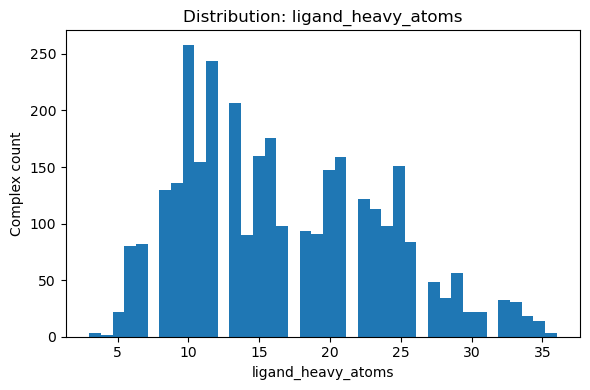

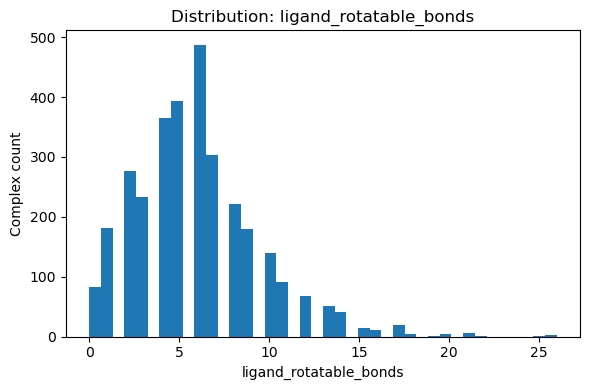

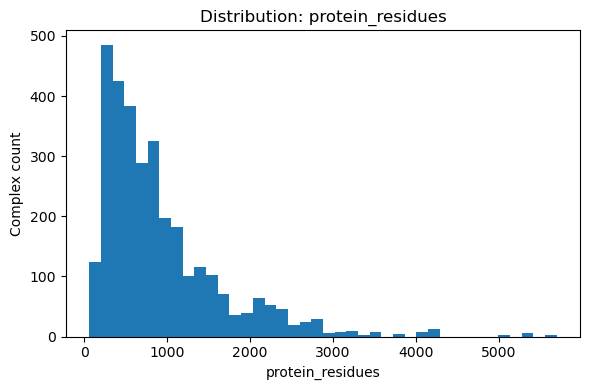

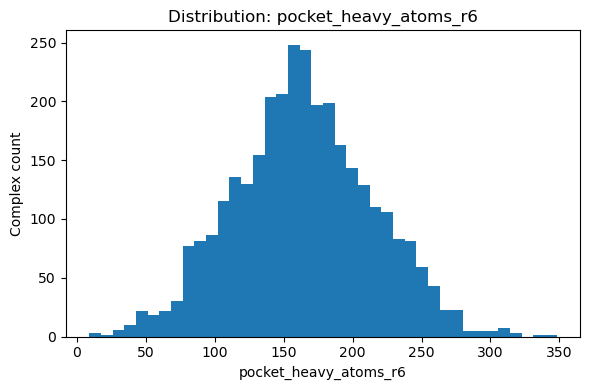

In [4]:

for feature in FEATURES:
    plt.figure(figsize=(6, 4))
    plt.hist(analysis[feature].dropna(), bins=40)
    plt.xlabel(feature)
    plt.ylabel("Complex count")
    plt.title(f"Distribution: {feature}")
    plt.tight_layout()
    plt.show()


,count,mean,std,25%,50%,75%,max
surfdock,3179.0,3.178285,0.809052,2.546243,3.027440,3.706621,7.276286
unimol,3179.0,22.026571,4.176817,19.110000,21.650000,24.335000,55.220000
diffdock,3179.0,30.149476,12.056983,21.452184,29.102863,37.085876,99.162905
diffdock_l,3179.0,28.001163,11.551889,19.564596,27.109111,34.775995,90.837141
gnina,3179.0,4.953672,8.340480,2.377275,3.608358,5.523969,259.143132
autodock,3179.0,48.367409,193.525231,7.656431,12.003860,19.320119,3547.965529
smina,3179.0,2.826719,2.761219,0.979093,1.743825,3.704165,22.772781


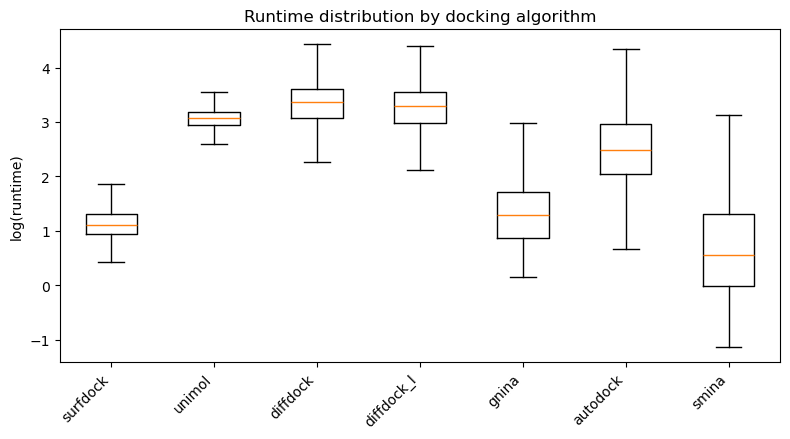

In [5]:

runtime_summary = (
    analysis[RUNTIME_COLS]
    .rename(columns=lambda c: c.removesuffix("_runtime"))
    .describe(percentiles=[0.25, 0.5, 0.75])
    .T[["count", "mean", "std", "25%", "50%", "75%", "max"]]
)
display(runtime_summary)

plt.figure(figsize=(8, 4.5))
plt.boxplot(
    [np.log(analysis[f"{a}_runtime"].dropna()) for a in ALGORITHMS],
    tick_labels=ALGORITHMS,
    showfliers=False,
)
plt.xticks(rotation=45, ha="right")
plt.ylabel("log(runtime)")
plt.title("Runtime distribution by docking algorithm")
plt.tight_layout()
plt.show()



## 3. Monotonic associations: Spearman correlation

Runtime is strongly right-skewed for several methods, and the physical relationships need not be linear. Spearman's \(\rho\) is therefore used as the primary univariate association measure.

The first heatmap asks the directly relevant question: **which physical descriptors track runtime for which docking algorithms?**


,surfdock,unimol,diffdock,diffdock_l,gnina,autodock,smina
ligand_heavy_atoms,0.872,0.287,0.414,0.288,0.607,0.337,0.906
ligand_rotatable_bonds,0.562,0.337,0.373,0.239,0.544,0.309,0.700
protein_residues,0.048,0.405,0.774,0.527,0.558,0.167,0.057
pocket_heavy_atoms_r6,0.692,0.192,0.470,0.343,0.510,0.551,0.624


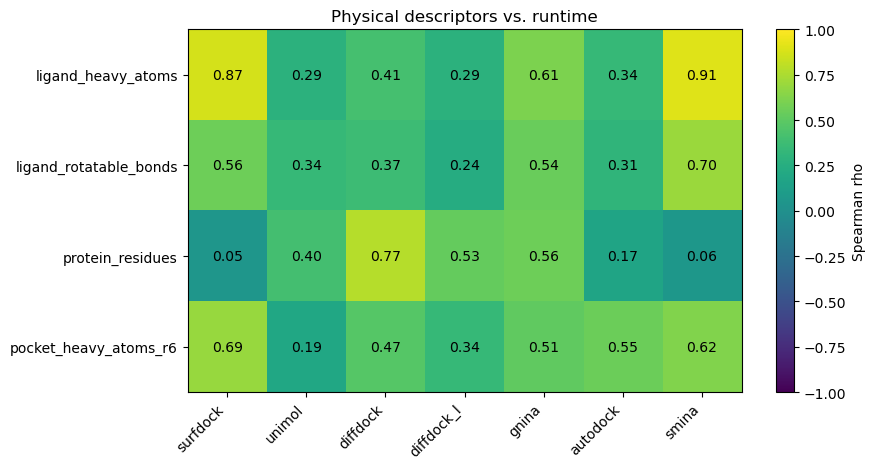

In [6]:

spearman = pd.DataFrame(index=FEATURES, columns=ALGORITHMS, dtype=float)

for feature in FEATURES:
    for algorithm in ALGORITHMS:
        spearman.loc[feature, algorithm] = analysis[feature].corr(
            analysis[f"{algorithm}_runtime"], method="spearman"
        )

display(spearman.round(3))

plt.figure(figsize=(9, 4.8))
img = plt.imshow(spearman.values, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(img, label="Spearman rho")
plt.xticks(range(len(ALGORITHMS)), ALGORITHMS, rotation=45, ha="right")
plt.yticks(range(len(FEATURES)), FEATURES)
plt.title("Physical descriptors vs. runtime")
for i in range(spearman.shape[0]):
    for j in range(spearman.shape[1]):
        plt.text(j, i, f"{spearman.iloc[i, j]:.2f}", ha="center", va="center")
plt.tight_layout()
plt.show()


The descriptor-only heatmap checks redundancy among the proposed physical variables before interpreting multivariate coefficients.

,ligand_heavy_atoms,ligand_rotatable_bonds,protein_residues,pocket_heavy_atoms_r6
ligand_heavy_atoms,1.000,0.577,-0.034,0.563
ligand_rotatable_bonds,0.577,1.000,0.119,0.402
protein_residues,-0.034,0.119,1.000,0.151
pocket_heavy_atoms_r6,0.563,0.402,0.151,1.000


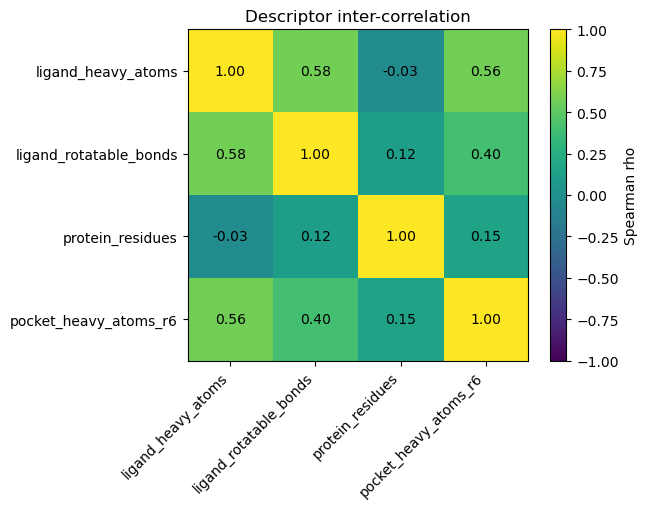

In [7]:

feature_corr = analysis[FEATURES].corr(method="spearman")
display(feature_corr.round(3))

plt.figure(figsize=(6.5, 5.2))
img = plt.imshow(feature_corr.values, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(img, label="Spearman rho")
plt.xticks(range(len(FEATURES)), FEATURES, rotation=45, ha="right")
plt.yticks(range(len(FEATURES)), FEATURES)
plt.title("Descriptor inter-correlation")
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        plt.text(j, i, f"{feature_corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.tight_layout()
plt.show()



## 4. Interpretable predictive test: nested linear models

To determine whether the descriptors provide useful runtime signal beyond pairwise correlations, fit simple linear regressions to **log runtime**.

Three nested feature sets isolate where predictive value comes from:

1. **Ligand only:** heavy atoms + rotatable bonds.
2. **+ global protein size:** adds total residue count.
3. **+ local pocket:** adds pocket heavy atoms + pocket-box volume.

A five-fold split over complexes is held fixed across all docking algorithms. The goal is not to maximise prediction accuracy, but to test whether each physically motivated descriptor family contributes stable, out-of-sample signal.


In [8]:

FEATURE_SETS = {
    "ligand": [
        "ligand_heavy_atoms",
        "ligand_rotatable_bonds",
    ],
    "ligand+protein": [
        "ligand_heavy_atoms",
        "ligand_rotatable_bonds",
        "protein_residues",
    ],
    "ligand+protein+pocket": FEATURES,
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
splits = list(kf.split(analysis))

records = []

for algorithm in ALGORITHMS:
    y_all = np.log(analysis[f"{algorithm}_runtime"].to_numpy())

    for model_name, feature_names in FEATURE_SETS.items():
        X_all = analysis[feature_names].to_numpy(dtype=float)

        fold_r2, fold_mae = [], []

        for train_idx, test_idx in splits:
            X_train, X_test = X_all[train_idx], X_all[test_idx]
            y_train, y_test = y_all[train_idx], y_all[test_idx]

            valid_train = np.isfinite(X_train).all(axis=1) & np.isfinite(y_train)
            valid_test = np.isfinite(X_test).all(axis=1) & np.isfinite(y_test)

            model = make_pipeline(StandardScaler(), LinearRegression())
            model.fit(X_train[valid_train], y_train[valid_train])

            pred = model.predict(X_test[valid_test])
            fold_r2.append(r2_score(y_test[valid_test], pred))
            fold_mae.append(mean_absolute_error(y_test[valid_test], pred))

        records.append({
            "algorithm": algorithm,
            "feature_set": model_name,
            "r2_log_mean": np.mean(fold_r2),
            "r2_log_sd": np.std(fold_r2),
            "mae_log_mean": np.mean(fold_mae),
            "mae_log_sd": np.std(fold_mae),
        })

cv_results = pd.DataFrame(records)
cv_results.to_csv(OUTPUT_DIR / "linear_cv_results.csv", index=False)

display(
    cv_results
    .pivot(index="algorithm", columns="feature_set", values="r2_log_mean")
    .round(3)
)


feature_set,ligand,ligand+protein,ligand+protein+pocket
algorithm,,,
autodock,0.054,0.078,0.233
diffdock,0.202,0.572,0.606
diffdock_l,0.095,0.269,0.291
gnina,0.341,0.827,0.829
smina,0.882,0.885,0.893
surfdock,0.714,0.719,0.771
unimol,0.152,0.354,0.364


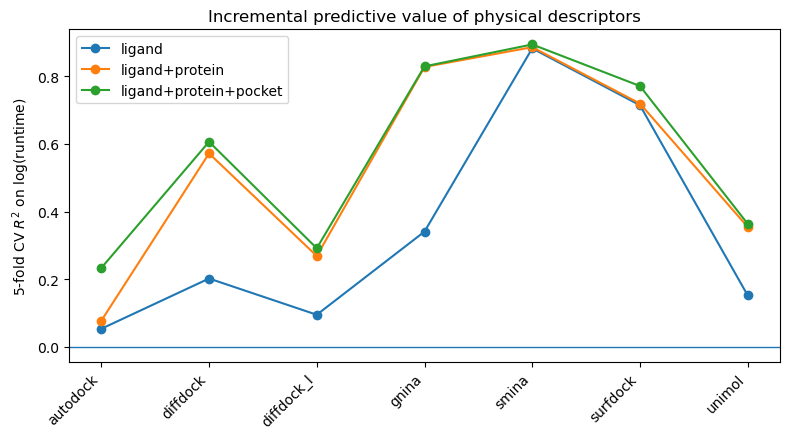

In [9]:

r2_table = cv_results.pivot(
    index="algorithm", columns="feature_set", values="r2_log_mean"
)

plt.figure(figsize=(8, 4.5))
for feature_set in FEATURE_SETS:
    plt.plot(r2_table.index, r2_table[feature_set], marker="o", label=feature_set)
plt.axhline(0, linewidth=1)
plt.xticks(rotation=45, ha="right")
plt.ylabel("5-fold CV $R^2$ on log(runtime)")
plt.title("Incremental predictive value of physical descriptors")
plt.legend()
plt.tight_layout()
plt.show()



## 5. Standardised linear coefficients

The final model is fitted on all available complexes solely to inspect direction and relative magnitude of the associations. These coefficients are **descriptive**, not an unbiased estimate of predictive performance; the preceding cross-validation is the relevant generalisation test.


,surfdock,unimol,diffdock,diffdock_l,gnina,autodock,smina
ligand_heavy_atoms,0.162,0.048,0.123,0.089,0.281,0.026,0.569
ligand_rotatable_bonds,0.015,0.046,0.029,0.011,0.108,-0.078,0.247
protein_residues,0.008,0.086,0.236,0.167,0.430,0.095,0.038
pocket_heavy_atoms_r6,0.067,-0.023,0.091,0.078,0.031,0.523,0.092


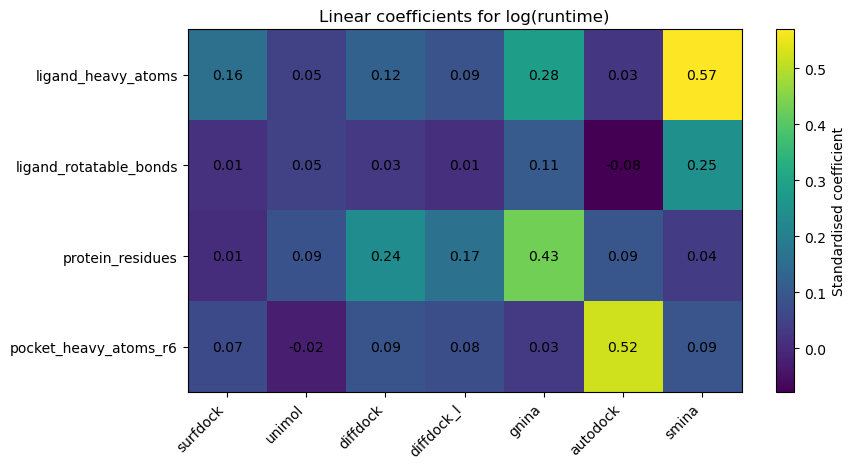

In [10]:

coef = pd.DataFrame(index=FEATURES, columns=ALGORITHMS, dtype=float)

for algorithm in ALGORITHMS:
    X = analysis[FEATURES].to_numpy(dtype=float)
    y = np.log(analysis[f"{algorithm}_runtime"].to_numpy())

    valid = np.isfinite(X).all(axis=1) & np.isfinite(y)
    model = make_pipeline(StandardScaler(), LinearRegression())
    model.fit(X[valid], y[valid])

    coef.loc[:, algorithm] = model.named_steps["linearregression"].coef_

display(coef.round(3))

plt.figure(figsize=(9, 4.8))
img = plt.imshow(coef.values, aspect="auto")
plt.colorbar(img, label="Standardised coefficient")
plt.xticks(range(len(ALGORITHMS)), ALGORITHMS, rotation=45, ha="right")
plt.yticks(range(len(FEATURES)), FEATURES)
plt.title("Linear coefficients for log(runtime)")
for i in range(coef.shape[0]):
    for j in range(coef.shape[1]):
        plt.text(j, i, f"{coef.iloc[i, j]:.2f}", ha="center", va="center")
plt.tight_layout()
plt.show()



## 6. Optional direct scatter plots

These are intentionally generated one figure at a time to avoid a large panel of repetitive plots. Select any algorithm/descriptor pair after inspecting the correlation table.


In [11]:

def plot_relation(feature, algorithm):
    x = analysis[feature].to_numpy(dtype=float)
    y = analysis[f"{algorithm}_runtime"].to_numpy(dtype=float)

    valid = np.isfinite(x) & np.isfinite(y) & (y > 0)

    plt.figure(figsize=(6, 4))
    plt.scatter(x[valid], np.log(y[valid]), s=12, alpha=0.35)
    plt.xlabel(feature)
    plt.ylabel("log(runtime)")
    plt.title(f"{algorithm}: runtime vs. {feature}")
    plt.tight_layout()
    plt.show()

# Example:
# plot_relation("ligand_rotatable_bonds", "autodock")



## 7. Compact interpretation guide

The analysis is intended to answer four practical questions for the later cost surrogate:

- **Are simple physical descriptors informative at all?**  
  Check the feature–runtime Spearman matrix and the ligand-only CV \(R^2\).

- **Does whole-protein size matter once ligand complexity is known?**  
  Compare `ligand` with `ligand+protein`.

- **Does a local pocket proxy add signal?**  
  Compare `ligand+protein` with `ligand+protein+pocket`.

- **Are the relationships algorithm-specific?**  
  Compare Spearman coefficients and standardised slopes across algorithm columns. Strong differences would support an algorithm-conditioned cost model rather than a single shared mapping.

A negative result is also useful: if the rich structural descriptors add little beyond an algorithm-specific baseline, a heavy ESM-C/ChemBERTa cost model is unlikely to be justified.

### Important follow-up if available

If the docking pipelines saved the actual per-complex search-box centre and side lengths, add those quantities directly. They are preferable to the ligand-centred pocket proxy because they correspond to the computation actually performed by the docking program.



# 8. Learned complex embeddings

Sean's current cost predictor uses, for each query \((i,a)\),

\[
[\;\overline{\mathbf z}^{\,P}_i;\ \mathbf z^{L}_i;\ \mathbf e_a\;],
\]

where \(\overline{\mathbf z}^{\,P}_i\) is the **mean** of the residue-level ESM-C-600M protein graph node features, \(\mathbf z^L_i\) is the ligand ChemBERTa vector, and \(\mathbf e_a\) is a seven-dimensional one-hot algorithm identifier.

The supplied examples have:
- protein graph node feature matrix `x`: **1152 dimensions per residue**;
- ligand ChemBERTa embedding: **384 dimensions**;
- concatenated complex embedding: **1536 dimensions** before the algorithm identifier.

A useful consequence of analysing the physical descriptors separately is that mean pooling does **not explicitly preserve node count**. In particular, total protein residue count is not directly encoded as a scalar by \(\operatorname{mean}_v \mathbf x_v\). Therefore, physical size descriptors may provide complementary cost information even when semantic embeddings are already used.


In [12]:

import torch
from sklearn.linear_model import RidgeCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

PROTEIN_GRAPH_DIR = DATA_ROOT / "protein_graphs_esmc_600m"

# Locate the MOAD ChemBERTa file without hard-coding a duplicate-upload suffix.
chem_candidates = [
    DATA_ROOT / "ligand_chemberta_moad3179.pt",
    DATA_ROOT / "ligand_chemberta_moad3179(1).pt",
]
chem_candidates += list(DATA_ROOT.glob("ligand_chemberta_moad3179*.pt"))
CHEMBERTA_PT = next((p for p in chem_candidates if p.exists()), None)

if CHEMBERTA_PT is None:
    raise FileNotFoundError(
        "Could not locate ligand_chemberta_moad3179*.pt under DATA_ROOT. "
        "Set CHEMBERTA_PT manually."
    )

EMBED_CACHE = OUTPUT_DIR / "moad_complex_embeddings_mean_esmc600m.pt"
RIDGE_ALPHAS = np.logspace(-3, 3, 13)


def resolve_protein_graph(identifier):
    candidates = [
        PROTEIN_GRAPH_DIR / f"pyg_graph_{identifier}_esmc_600m.pt",
        PROTEIN_GRAPH_DIR / f"{identifier}_esmc_600m.pt",
        PROTEIN_GRAPH_DIR / f"pyg_graph_{identifier}.pt",
        PROTEIN_GRAPH_DIR / f"{identifier}.pt",
    ]
    return next((p for p in candidates if p.exists()), None)


def load_complex_embeddings():
    if EMBED_CACHE.exists():
        cache = torch.load(EMBED_CACHE, map_location="cpu", weights_only=False)
        if cache["ids"] == analysis["PDB_CCD_ID"].tolist():
            return (
                cache["protein"].numpy(),
                cache["ligand"].numpy(),
            )

    chem = torch.load(CHEMBERTA_PT, map_location="cpu", weights_only=False)
    ligand_lookup = {
        identifier: emb
        for identifier, emb in zip(chem["ligand_ids"], chem["embeddings"])
    }

    protein_rows, ligand_rows, kept_ids, issues = [], [], [], []

    for identifier in analysis["PDB_CCD_ID"]:
        graph_path = resolve_protein_graph(identifier)
        if graph_path is None or identifier not in ligand_lookup:
            issues.append(identifier)
            continue

        graph = torch.load(graph_path, map_location="cpu", weights_only=False)
        protein_rows.append(graph.x.float().mean(dim=0))
        ligand_rows.append(ligand_lookup[identifier].float())
        kept_ids.append(identifier)

    if issues:
        print(f"Embedding files missing for {len(issues)} complexes.")
        print("First missing IDs:", issues[:10])

    cache = {
        "ids": kept_ids,
        "protein": torch.stack(protein_rows),
        "ligand": torch.stack(ligand_rows),
    }
    torch.save(cache, EMBED_CACHE)

    # Reorder/filter the main analysis table to exactly match the cached arrays.
    return cache["protein"].numpy(), cache["ligand"].numpy()


protein_emb, ligand_emb = load_complex_embeddings()

embed_cache = torch.load(EMBED_CACHE, map_location="cpu", weights_only=False)
embed_ids = embed_cache["ids"]

analysis_emb = (
    analysis
    .set_index("PDB_CCD_ID")
    .loc[embed_ids]
    .reset_index()
)

protein_emb = embed_cache["protein"].numpy()
ligand_emb = embed_cache["ligand"].numpy()
complex_emb = np.concatenate([protein_emb, ligand_emb], axis=1)

print("Complexes:", len(analysis_emb))
print("Protein mean embedding:", protein_emb.shape)
print("Ligand ChemBERTa:", ligand_emb.shape)
print("Concatenated complex embedding:", complex_emb.shape)


/srv/conda/envs/as_bbo/as_dock/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/srv/conda/envs/as_bbo/as_dock/lib/python3.10/site-packages/transformers/utils/hub.py:110: FutureWarning: Using `TRANSFORMERS_CACHE` is deprecated and will be removed in v5 of Transformers. Use `HF_HOME` instead.
  warnings.warn(


Complexes: 3179
Protein mean embedding: (3179, 1152)
Ligand ChemBERTa: (3179, 384)
Concatenated complex embedding: (3179, 1536)



## 9. Linear probes: how much runtime signal is recoverable?

For each docking algorithm separately, fit ridge regressions to \(\log C_{ia}\) using the **same five complex-wise folds** for:

1. physical descriptors only;
2. protein ESM-C mean embedding only;
3. ligand ChemBERTa only;
4. concatenated protein + ligand embedding;
5. concatenated embedding + physical descriptors.

Ridge regression is used rather than ordinary least squares because the learned representation has 1,536 correlated dimensions. This is a **probe**, not the final cost model: a high cross-validated \(R^2\) demonstrates that runtime-relevant information is readily recoverable from the representation; a low value does not prove that a nonlinear predictor could not extract more.


In [ ]:

PHYSICAL_CORE = [
    "ligand_heavy_atoms",
    "ligand_rotatable_bonds",
    "protein_residues",
    f"pocket_heavy_atoms_r{r}",
]

X_physical = analysis_emb[PHYSICAL_CORE].to_numpy(dtype=float)

PROBE_SETS = {
    "physical": X_physical,
    "protein_ESMC_mean": protein_emb,
    "ligand_ChemBERTa": ligand_emb,
    "complex_embedding": complex_emb,
    "complex+physical": np.concatenate([complex_emb, X_physical], axis=1),
}

kf_emb = KFold(n_splits=5, shuffle=True, random_state=42)
emb_splits = list(kf_emb.split(analysis_emb))

probe_records = []

for algorithm in tqdm(ALGORITHMS):
    y = np.log(analysis_emb[f"{algorithm}_runtime"].to_numpy(dtype=float))

    for name, X in PROBE_SETS.items():
        fold_r2, fold_mae = [], []

        for train_idx, test_idx in emb_splits:
            model = make_pipeline(
                StandardScaler(),
                RidgeCV(alphas=RIDGE_ALPHAS),
            )
            model.fit(X[train_idx], y[train_idx])
            pred = model.predict(X[test_idx])

            fold_r2.append(r2_score(y[test_idx], pred))
            fold_mae.append(mean_absolute_error(y[test_idx], pred))

        probe_records.append({
            "algorithm": algorithm,
            "representation": name,
            "r2_log_mean": np.mean(fold_r2),
            "r2_log_sd": np.std(fold_r2),
            "mae_log_mean": np.mean(fold_mae),
            "mae_log_sd": np.std(fold_mae),
        })

probe_results = pd.DataFrame(probe_records)
probe_results.to_csv(OUTPUT_DIR / "embedding_linear_probe_results.csv", index=False)

probe_r2 = probe_results.pivot(
    index="algorithm",
    columns="representation",
    values="r2_log_mean",
)

display(probe_r2.round(3))


representation,complex+physical,complex_embedding,ligand_ChemBERTa,physical,protein_ESMC_mean
algorithm,,,,,
autodock,0.592,0.508,0.295,0.233,0.392
diffdock,0.822,0.731,0.353,0.606,0.593
diffdock_l,0.362,0.314,0.144,0.292,0.260
gnina,0.851,0.663,0.421,0.829,0.420
smina,0.950,0.909,0.908,0.893,0.399
surfdock,0.759,0.707,0.706,0.771,0.302
unimol,0.322,0.231,0.156,0.364,0.131


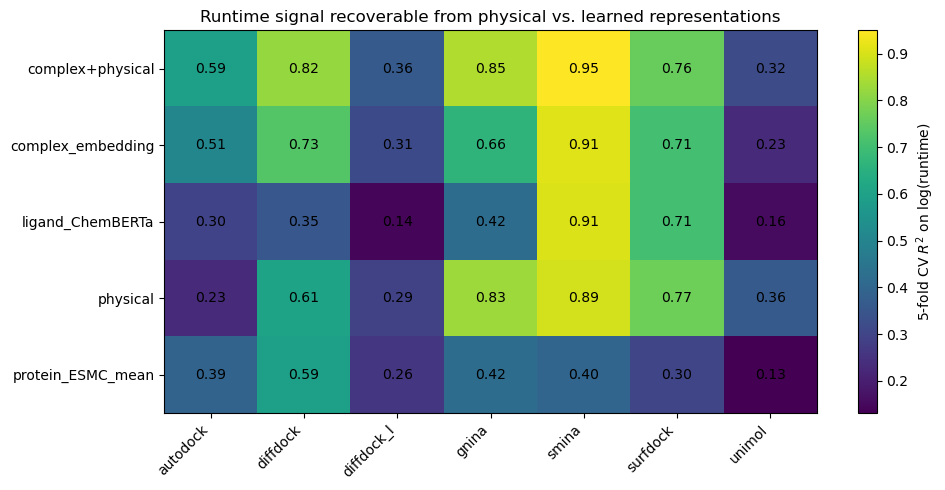

In [14]:

plt.figure(figsize=(10, 5))
img = plt.imshow(probe_r2.T.values, aspect="auto")
plt.colorbar(img, label="5-fold CV $R^2$ on log(runtime)")
plt.xticks(range(len(probe_r2.index)), probe_r2.index, rotation=45, ha="right")
plt.yticks(range(len(probe_r2.columns)), probe_r2.columns)
plt.title("Runtime signal recoverable from physical vs. learned representations")
for i in range(probe_r2.shape[1]):
    for j in range(probe_r2.shape[0]):
        plt.text(j, i, f"{probe_r2.T.iloc[i, j]:.2f}", ha="center", va="center")
plt.tight_layout()
plt.show()



### Complementarity

The key comparison is

\[
R^2(\text{complex embedding + physical})
-
R^2(\text{complex embedding}).
\]

A positive increment means that explicitly supplied size/complexity descriptors contain runtime information that is **not easily linearly recoverable from Sean's current mean-pooled ESM-C + ChemBERTa representation**.


,embedding_r2,embedding+physical_r2,delta_r2
algorithm,,,
autodock,0.508,0.592,0.085
diffdock,0.731,0.822,0.090
diffdock_l,0.314,0.362,0.048
gnina,0.663,0.851,0.188
smina,0.909,0.950,0.041
surfdock,0.707,0.759,0.053
unimol,0.231,0.322,0.091


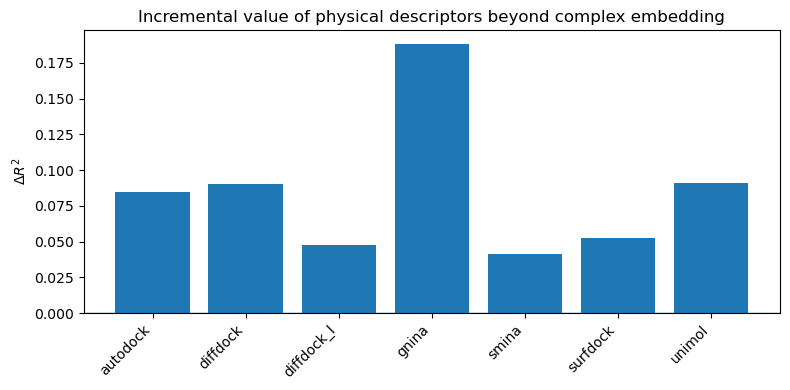

In [15]:

complementarity = pd.DataFrame({
    "embedding_r2": probe_r2["complex_embedding"],
    "embedding+physical_r2": probe_r2["complex+physical"],
})
complementarity["delta_r2"] = (
    complementarity["embedding+physical_r2"]
    - complementarity["embedding_r2"]
)
display(complementarity.round(3))

plt.figure(figsize=(8, 4))
plt.bar(complementarity.index, complementarity["delta_r2"])
plt.axhline(0, linewidth=1)
plt.xticks(rotation=45, ha="right")
plt.ylabel(r"$\Delta R^2$")
plt.title("Incremental value of physical descriptors beyond complex embedding")
plt.tight_layout()
plt.show()



## 10. Do the learned embeddings already encode the physical quantities?

This diagnostic bridges the two analyses directly. Each physical descriptor is predicted from the learned representation using five-fold ridge regression.

Interpretation:

- high \(R^2\): the physical quantity is already readily recoverable from the embedding;
- low \(R^2\): explicitly appending the descriptor may be useful, especially if that descriptor is strongly related to runtime.

The decomposition into protein, ligand, and concatenated embeddings also checks whether the signal appears on the expected molecular side.


embedding,complex_embedding,ligand_ChemBERTa,protein_ESMC_mean
descriptor,,,
ligand_heavy_atoms,0.956,0.958,0.399
ligand_rotatable_bonds,0.902,0.902,0.398
pocket_heavy_atoms_r6,0.578,0.429,0.368
protein_residues,0.678,0.192,0.648


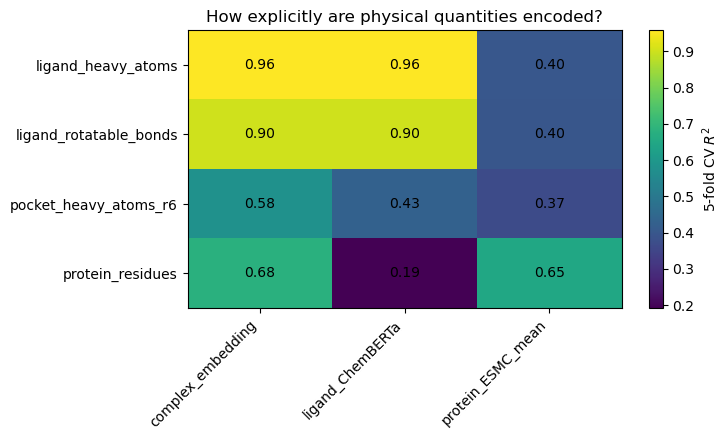

In [16]:

descriptor_probe_records = []

EMBED_SETS = {
    "protein_ESMC_mean": protein_emb,
    "ligand_ChemBERTa": ligand_emb,
    "complex_embedding": complex_emb,
}

for descriptor in PHYSICAL_CORE:
    y = analysis_emb[descriptor].to_numpy(dtype=float)

    for name, X in EMBED_SETS.items():
        fold_r2 = []

        for train_idx, test_idx in emb_splits:
            model = make_pipeline(
                StandardScaler(),
                RidgeCV(alphas=RIDGE_ALPHAS),
            )
            model.fit(X[train_idx], y[train_idx])
            pred = model.predict(X[test_idx])
            fold_r2.append(r2_score(y[test_idx], pred))

        descriptor_probe_records.append({
            "descriptor": descriptor,
            "embedding": name,
            "r2_mean": np.mean(fold_r2),
            "r2_sd": np.std(fold_r2),
        })

descriptor_probe = pd.DataFrame(descriptor_probe_records)
descriptor_probe.to_csv(
    OUTPUT_DIR / "physical_descriptor_from_embedding_probe.csv",
    index=False,
)

descriptor_probe_r2 = descriptor_probe.pivot(
    index="descriptor",
    columns="embedding",
    values="r2_mean",
)

display(descriptor_probe_r2.round(3))

plt.figure(figsize=(7.5, 4.5))
img = plt.imshow(descriptor_probe_r2.values, aspect="auto")
plt.colorbar(img, label="5-fold CV $R^2$")
plt.xticks(
    range(len(descriptor_probe_r2.columns)),
    descriptor_probe_r2.columns,
    rotation=45,
    ha="right",
)
plt.yticks(range(len(descriptor_probe_r2.index)), descriptor_probe_r2.index)
plt.title("How explicitly are physical quantities encoded?")
for i in range(descriptor_probe_r2.shape[0]):
    for j in range(descriptor_probe_r2.shape[1]):
        plt.text(
            j, i, f"{descriptor_probe_r2.iloc[i, j]:.2f}",
            ha="center", va="center"
        )
plt.tight_layout()
plt.show()



## 11. Algorithm interaction: is one shared physical-runtime relationship sufficient?

The earlier heatmaps already suggest that the same physical quantity affects different docking methods differently. This can be tested explicitly with a pooled query-level linear model.

Compare:

\[
\text{algorithm ID + physical descriptors}
\]

against

\[
\text{algorithm ID + algorithm}\times\text{physical-descriptor interactions}.
\]

The second model allows, for example, ligand heavy-atom count to have a different slope for Smina and DiffDock. Complex-wise cross-validation is essential: all seven algorithm queries for the same complex remain in the same fold.

This is the clean linear analogue of why Sean's nonlinear model receives the algorithm identifier alongside the molecular representation.


In [17]:

# Build query-level data while preserving complex-level folds.
n_complex = len(analysis_emb)
n_alg = len(ALGORITHMS)

phys = analysis_emb[PHYSICAL_CORE].to_numpy(dtype=float)
alg_eye = np.eye(n_alg)

X_shared = []
X_interacted = []
y_query = []
complex_index = []
algorithm_index = []

for i in range(n_complex):
    for a_idx, algorithm in enumerate(ALGORITHMS):
        p = phys[i]
        onehot = alg_eye[a_idx]

        # Shared physical slopes + algorithm intercepts.
        X_shared.append(np.concatenate([onehot, p]))

        # Explicit algorithm-specific physical slopes.
        interactions = np.outer(onehot, p).ravel()
        X_interacted.append(np.concatenate([onehot, p, interactions]))

        y_query.append(np.log(analysis_emb.loc[i, f"{algorithm}_runtime"]))
        complex_index.append(i)
        algorithm_index.append(a_idx)

X_shared = np.asarray(X_shared)
X_interacted = np.asarray(X_interacted)
y_query = np.asarray(y_query)
complex_index = np.asarray(complex_index)
algorithm_index = np.asarray(algorithm_index)

interaction_records = []

for name, X in {
    "shared_physical_slopes": X_shared,
    "algorithm_specific_physical_slopes": X_interacted,
}.items():
    fold_macro_r2 = []

    for train_complex, test_complex in emb_splits:
        train_mask = np.isin(complex_index, train_complex)
        test_mask = np.isin(complex_index, test_complex)

        model = make_pipeline(
            StandardScaler(),
            RidgeCV(alphas=RIDGE_ALPHAS),
        )
        model.fit(X[train_mask], y_query[train_mask])
        pred = model.predict(X[test_mask])

        per_algorithm_r2 = []
        test_alg = algorithm_index[test_mask]
        y_test = y_query[test_mask]

        for a_idx in range(n_alg):
            m = test_alg == a_idx
            per_algorithm_r2.append(r2_score(y_test[m], pred[m]))

        fold_macro_r2.append(np.mean(per_algorithm_r2))

    interaction_records.append({
        "model": name,
        "macro_r2_log_mean": np.mean(fold_macro_r2),
        "macro_r2_log_sd": np.std(fold_macro_r2),
    })

interaction_results = pd.DataFrame(interaction_records)
display(interaction_results.round(3))
interaction_results.to_csv(
    OUTPUT_DIR / "physical_algorithm_interaction_probe.csv",
    index=False,
)


,model,macro_r2_log_mean,macro_r2_log_sd
0,shared_physical_slopes,0.065,0.028
1,algorithm_specific_physical_slopes,0.570,0.009



## 12. Interpretation

This combined analysis is designed to support a small number of decisions:

1. **Physical vs. learned signal.**  
   Compare `physical` with `complex_embedding` per algorithm.

2. **Protein vs. ligand contribution.**  
   Compare `protein_ESMC_mean` and `ligand_ChemBERTa`.

3. **Complementarity.**  
   If `complex+physical` materially improves over `complex_embedding`, append the corresponding cheap physical quantities to the eventual cost predictor rather than expecting the latent representation to recover them implicitly.

4. **Algorithm dependence.**  
   If algorithm-specific physical slopes substantially outperform shared slopes—and the per-algorithm probe table shows similarly heterogeneous embedding performance—an interaction-capable cost model \(h(x_i,a)\) is justified.

5. **Mean-pooling limitation.**  
   If `protein_residues` is poorly decodable from the mean ESM-C representation yet materially predicts some algorithms' runtime, explicitly adding residue count or node count is preferable to changing the entire protein encoder merely to recover size.

### What this notebook deliberately does not claim

A linear probe measures **readily recoverable** information, not all information in a nonlinear embedding. Therefore, if the complex embedding performs weakly here, the correct conclusion is that the runtime relation is not strongly linear in the representation—not that Sean's nonlinear model cannot use it.

Conversely, if the simple physical model matches or exceeds the embedding probe for several algorithms, that is a strong reason to retain the physical descriptors as explicit, interpretable inputs and as a baseline for the final learned cost model.
